In [1]:

from google.colab import drive
from pathlib import Path
import zipfile

# Mount Google Drive
drive.mount('/content/drive')

ROOT = Path('/content/drive/MyDrive')


def browse_folders(path):
    path = Path(path)

    while True:
        folders = sorted(
            [p for p in path.iterdir() if p.is_dir()],
            key=lambda p: p.name.lower()
        )

        print(f"\n📂 Current location: {path}")
        print("\nFolders:")

        for i, folder in enumerate(folders):
            print(f"{i}: 📁 {folder.name}")

        print("\nOptions:")
        print("Enter a folder number to open it")
        print("'..' to go back")
        print("'s' to select this folder")

        choice = input("\nYour choice: ").strip().lower()

        if choice == 's':
            return path

        elif choice == '..':
            if path != ROOT:
                path = path.parent
            else:
                print("Already at the MyDrive root.")

        elif choice.isdigit() and int(choice) < len(folders):
            path = folders[int(choice)]

        else:
            print("Invalid choice. Try again.")


# Step 1: Browse to the folder containing your ZIP file
ZIP_PARENT = browse_folders(ROOT)

# Step 2: Display ZIP files in the selected folder
zip_files = sorted(
    ZIP_PARENT.glob("*.zip"),
    key=lambda p: p.name.lower()
)

if not zip_files:
    print(f"\nNo ZIP files found in: {ZIP_PARENT}")
    print("Run this cell again and select the correct folder.")

else:
    print("\n📦 Available ZIP files:")

    for i, zip_file in enumerate(zip_files):
        print(f"{i}: {zip_file.name}")

    # Step 3: Select the ZIP file
    while True:
        choice = input("\nEnter the ZIP file number: ").strip()

        if choice.isdigit() and int(choice) < len(zip_files):
            ZIP_PATH = zip_files[int(choice)]
            break

        print("Invalid selection. Try again.")

    # Step 4: Choose where to extract the ZIP
    print("\nSelected ZIP:", ZIP_PATH.name)
    print("1: Extract into a new folder with the ZIP's name")
    print("2: Extract into the selected parent folder")

    extract_choice = input("Choose extraction location (1/2): ").strip()

    if extract_choice == '2':
        PROJECT_ROOT = ZIP_PARENT
    else:
        PROJECT_ROOT = ZIP_PARENT / ZIP_PATH.stem

    # Step 5: Extract safely
    PROJECT_ROOT.mkdir(parents=True, exist_ok=True)

    with zipfile.ZipFile(ZIP_PATH, 'r') as z:
        # Prevent files in the ZIP from escaping the destination folder
        destination = PROJECT_ROOT.resolve()

        for member in z.infolist():
            target = (PROJECT_ROOT / member.filename).resolve()

            if target != destination and destination not in target.parents:
                raise ValueError(
                    f"Unsafe ZIP entry detected: {member.filename}"
                )

        z.extractall(PROJECT_ROOT)

    print("\n✅ Extraction completed!")
    print("ZIP file:", ZIP_PATH)
    print("Project folder:", PROJECT_ROOT)

    print("\n📂 Project contents:")

    for item in sorted(PROJECT_ROOT.iterdir())[:30]:
        print("📁" if item.is_dir() else "📄", item.name)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

📂 Current location: /content/drive/MyDrive

Folders:
0: 📁 Classroom
1: 📁 Colab Notebooks
2: 📁 Docs
3: 📁 handwriting_project
4: 📁 Mdm Img Processing
5: 📁 ML Handwriting Dataset
6: 📁 My docs
7: 📁 Nss pics
8: 📁 PD Patil bank Awareness session
9: 📁 SY
10: 📁 SY fees
11: 📁 vaish khade docs

Options:
Enter a folder number to open it
'..' to go back
's' to select this folder

Your choice: 5

📂 Current location: /content/drive/MyDrive/ML Handwriting Dataset

Folders:
0: 📁 dataset

Options:
Enter a folder number to open it
'..' to go back
's' to select this folder

Your choice: s

📦 Available ZIP files:
0: archive.zip
1: dataset.zip
2: handwritten_sentences.zip

Enter the ZIP file number: 1

Selected ZIP: dataset.zip
1: Extract into a new folder with the ZIP's name
2: Extract into the selected parent folder
Choose extraction location (1/2): 2

✅ Extraction completed!


In [2]:
from pathlib import Path

DATASET_ROOT = PROJECT_ROOT / "dataset"

PATCH_METADATA_PATH = (
    DATASET_ROOT / "processed" / "patch_metadata_224.csv"
)

RATINGS_PATH = None

# Search for the ratings workbook inside the selected project
rating_files = list(PROJECT_ROOT.rglob("ratingsFinal.xlsx"))

print("Dataset root:", DATASET_ROOT)
print("Patch metadata exists:", PATCH_METADATA_PATH.exists())
print("\nRatings workbooks found:")

for i, path in enumerate(rating_files):
    print(f"{i}: {path}")

if len(rating_files) == 1:
    RATINGS_PATH = rating_files[0]
elif len(rating_files) > 1:
    index = int(input("Enter the index of the correct ratings workbook: "))
    RATINGS_PATH = rating_files[index]

if RATINGS_PATH is not None:
    print("\nSelected ratings file:", RATINGS_PATH)

Dataset root: /content/drive/MyDrive/ML Handwriting Dataset/dataset
Patch metadata exists: True

Ratings workbooks found:
0: /content/drive/MyDrive/ML Handwriting Dataset/dataset/ratingsFinal.xlsx

Selected ratings file: /content/drive/MyDrive/ML Handwriting Dataset/dataset/ratingsFinal.xlsx


In [3]:
assert DATASET_ROOT.exists(), "Dataset folder not found."
assert PATCH_METADATA_PATH.exists(), (
    "Patch metadata CSV not found. Run Notebook 2 first."
)
assert RATINGS_PATH is not None and RATINGS_PATH.exists(), (
    "ratingsFinal.xlsx was not found."
)

print("All required files are available.")

All required files are available.


In [4]:
!pip -q install openpyxl scikit-learn seaborn

In [5]:
import random
import copy
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image
from pathlib import Path

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

OUTPUT_DIR = DATASET_ROOT / "processed" / "rating_prediction"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Device:", DEVICE)
print("Output directory:", OUTPUT_DIR)

Device: cuda
Output directory: /content/drive/MyDrive/ML Handwriting Dataset/dataset/processed/rating_prediction


In [6]:
ratings_df = pd.read_excel(RATINGS_PATH)
patch_df = pd.read_csv(PATCH_METADATA_PATH)

print("Ratings shape:", ratings_df.shape)
print("Ratings columns:", ratings_df.columns.tolist())

display(ratings_df.head())
display(patch_df.head())

Ratings shape: (422, 4)
Ratings columns: ['filename', 'rating', 'pratik rating', 'avg']


,filename,rating,pratik rating,avg
0,page001.jpg,7,7,7.0
1,page002.jpg,7,6,6.5
2,page003.jpg,6,6,6.0
3,page004.jpg,7,5,6.0
4,page005.jpg,7,7,7.0


,page_id,filename,source_path,processed_page_path,patch_index,x,y,source_width,source_height,patch_size,stride,patch_path,patch_reprocessed,patch_path_224,target_size,resize_status
0,page001_8795ef1ce0,page001.jpg,C:\Users\SWARA\Documents\Handwriting Analysis\...,C:\Users\SWARA\Documents\Handwriting Analysis\...,0,0,0,1898,2628,640,480,C:\Users\SWARA\Documents\Handwriting Analysis\...,False,C:\Users\SWARA\Documents\Handwriting Analysis\...,224,success
1,page001_8795ef1ce0,page001.jpg,C:\Users\SWARA\Documents\Handwriting Analysis\...,C:\Users\SWARA\Documents\Handwriting Analysis\...,1,480,0,1898,2628,640,480,C:\Users\SWARA\Documents\Handwriting Analysis\...,False,C:\Users\SWARA\Documents\Handwriting Analysis\...,224,success
2,page001_8795ef1ce0,page001.jpg,C:\Users\SWARA\Documents\Handwriting Analysis\...,C:\Users\SWARA\Documents\Handwriting Analysis\...,2,960,0,1898,2628,640,480,C:\Users\SWARA\Documents\Handwriting Analysis\...,False,C:\Users\SWARA\Documents\Handwriting Analysis\...,224,success
3,page001_8795ef1ce0,page001.jpg,C:\Users\SWARA\Documents\Handwriting Analysis\...,C:\Users\SWARA\Documents\Handwriting Analysis\...,3,1258,0,1898,2628,640,480,C:\Users\SWARA\Documents\Handwriting Analysis\...,False,C:\Users\SWARA\Documents\Handwriting Analysis\...,224,success
4,page001_8795ef1ce0,page001.jpg,C:\Users\SWARA\Documents\Handwriting Analysis\...,C:\Users\SWARA\Documents\Handwriting Analysis\...,4,0,480,1898,2628,640,480,C:\Users\SWARA\Documents\Handwriting Analysis\...,False,C:\Users\SWARA\Documents\Handwriting Analysis\...,224,success


In [7]:
TARGET_COL = "avg"
RATING_FILENAME_COL = "filename"

required_rating_cols = {RATING_FILENAME_COL, TARGET_COL}
required_patch_cols = {"filename", "patch_path", "source_path"}

assert required_rating_cols.issubset(ratings_df.columns), (
    f"Missing rating columns: {required_rating_cols - set(ratings_df.columns)}"
)

assert required_patch_cols.issubset(patch_df.columns), (
    f"Missing patch columns: {required_patch_cols - set(patch_df.columns)}"
)

def normalize_filename(value):
    return Path(str(value).replace("\\", "/")).name.strip().casefold()

ratings_df["match_key"] = ratings_df[RATING_FILENAME_COL].map(normalize_filename)
patch_df["match_key"] = patch_df["filename"].map(normalize_filename)

ratings_df[TARGET_COL] = pd.to_numeric(
    ratings_df[TARGET_COL], errors="coerce"
)

ratings_df = ratings_df.dropna(subset=[TARGET_COL]).copy()

# Stop if a filename has conflicting ratings.
conflicts = ratings_df.groupby("match_key")[TARGET_COL].nunique()
conflicts = conflicts[conflicts > 1]

if len(conflicts):
    raise ValueError(
        "Some filenames have conflicting ratings. Resolve these before training:\n"
        + str(conflicts)
    )

ratings_lookup = ratings_df.drop_duplicates("match_key").set_index("match_key")[TARGET_COL]

patch_df["target"] = patch_df["match_key"].map(ratings_lookup)

print("Total patches:", len(patch_df))
print("Patches with ratings:", patch_df["target"].notna().sum())
print("Patches without ratings:", patch_df["target"].isna().sum())

display(patch_df[["filename", "patch_path", "target"]].head())

Total patches: 12851
Patches with ratings: 12493
Patches without ratings: 358


,filename,patch_path,target
0,page001.jpg,C:\Users\SWARA\Documents\Handwriting Analysis\...,7.0
1,page001.jpg,C:\Users\SWARA\Documents\Handwriting Analysis\...,7.0
2,page001.jpg,C:\Users\SWARA\Documents\Handwriting Analysis\...,7.0
3,page001.jpg,C:\Users\SWARA\Documents\Handwriting Analysis\...,7.0
4,page001.jpg,C:\Users\SWARA\Documents\Handwriting Analysis\...,7.0


In [8]:
duplicate_names = ratings_df[
    ratings_df["match_key"].duplicated(keep=False)
].sort_values("match_key")

print("Repeated rating filenames:", len(duplicate_names))

display(duplicate_names[[RATING_FILENAME_COL, TARGET_COL]].head(20))

Repeated rating filenames: 0


,filename,avg


In [10]:
print("PROJECT_ROOT:", PROJECT_ROOT)
print("DATASET_ROOT:", DATASET_ROOT)

print("\nPatch metadata columns:")
print(patch_df.columns.tolist())

print("\nSample stored patch paths:")
display(patch_df[["patch_path", "source_path"]].head(10))

print("\nSample resolved patch paths:")
display(
    patch_df[["patch_path", "source_path"]]
    .head(10)
)

PROJECT_ROOT: /content/drive/MyDrive/ML Handwriting Dataset
DATASET_ROOT: /content/drive/MyDrive/ML Handwriting Dataset/dataset

Patch metadata columns:
['page_id', 'filename', 'source_path', 'processed_page_path', 'patch_index', 'x', 'y', 'source_width', 'source_height', 'patch_size', 'stride', 'patch_path', 'patch_reprocessed', 'patch_path_224', 'target_size', 'resize_status', 'match_key', 'target', 'patch_exists']

Sample stored patch paths:


,patch_path,source_path
0,/content/drive/MyDrive/ML Handwriting Dataset/...,/content/drive/MyDrive/ML Handwriting Dataset/...
1,/content/drive/MyDrive/ML Handwriting Dataset/...,/content/drive/MyDrive/ML Handwriting Dataset/...
2,/content/drive/MyDrive/ML Handwriting Dataset/...,/content/drive/MyDrive/ML Handwriting Dataset/...
3,/content/drive/MyDrive/ML Handwriting Dataset/...,/content/drive/MyDrive/ML Handwriting Dataset/...
4,/content/drive/MyDrive/ML Handwriting Dataset/...,/content/drive/MyDrive/ML Handwriting Dataset/...
5,/content/drive/MyDrive/ML Handwriting Dataset/...,/content/drive/MyDrive/ML Handwriting Dataset/...
6,/content/drive/MyDrive/ML Handwriting Dataset/...,/content/drive/MyDrive/ML Handwriting Dataset/...
7,/content/drive/MyDrive/ML Handwriting Dataset/...,/content/drive/MyDrive/ML Handwriting Dataset/...
8,/content/drive/MyDrive/ML Handwriting Dataset/...,/content/drive/MyDrive/ML Handwriting Dataset/...
9,/content/drive/MyDrive/ML Handwriting Dataset/...,/content/drive/MyDrive/ML Handwriting Dataset/...



Sample resolved patch paths:


,patch_path,source_path
0,/content/drive/MyDrive/ML Handwriting Dataset/...,/content/drive/MyDrive/ML Handwriting Dataset/...
1,/content/drive/MyDrive/ML Handwriting Dataset/...,/content/drive/MyDrive/ML Handwriting Dataset/...
2,/content/drive/MyDrive/ML Handwriting Dataset/...,/content/drive/MyDrive/ML Handwriting Dataset/...
3,/content/drive/MyDrive/ML Handwriting Dataset/...,/content/drive/MyDrive/ML Handwriting Dataset/...
4,/content/drive/MyDrive/ML Handwriting Dataset/...,/content/drive/MyDrive/ML Handwriting Dataset/...
5,/content/drive/MyDrive/ML Handwriting Dataset/...,/content/drive/MyDrive/ML Handwriting Dataset/...
6,/content/drive/MyDrive/ML Handwriting Dataset/...,/content/drive/MyDrive/ML Handwriting Dataset/...
7,/content/drive/MyDrive/ML Handwriting Dataset/...,/content/drive/MyDrive/ML Handwriting Dataset/...
8,/content/drive/MyDrive/ML Handwriting Dataset/...,/content/drive/MyDrive/ML Handwriting Dataset/...
9,/content/drive/MyDrive/ML Handwriting Dataset/...,/content/drive/MyDrive/ML Handwriting Dataset/...


In [11]:
from pathlib import Path

print("Searching for patch directories...")

for folder in PROJECT_ROOT.rglob("*"):
    if folder.is_dir() and folder.name in {
        "efficientnet_patches_224",
        "efficientnet_patches",
        "patches"
    }:
        print(folder)

print("\nSearching for patch metadata files...")

for file in PROJECT_ROOT.rglob("patch_metadata*.csv"):
    print(file)

Searching for patch directories...
/content/drive/MyDrive/ML Handwriting Dataset/dataset/processed/efficientnet_patches_224
/content/drive/MyDrive/ML Handwriting Dataset/dataset/processed/efficientnet_patches
/content/drive/MyDrive/ML Handwriting Dataset/dataset/dataset/processed/efficientnet_patches

Searching for patch metadata files...
/content/drive/MyDrive/ML Handwriting Dataset/dataset/processed/patch_metadata.csv
/content/drive/MyDrive/ML Handwriting Dataset/dataset/processed/patch_metadata_224.csv


In [12]:
import os
from pathlib import Path

# Index image files by filename once, rather than searching repeatedly.
IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp",
    ".tif", ".tiff", ".webp"
}

print("Indexing image files. This may take a moment...")

image_index = {}

for root, dirs, files in os.walk(PROJECT_ROOT):
    for filename in files:
        if Path(filename).suffix.lower() in IMAGE_EXTENSIONS:
            image_index.setdefault(filename.casefold(), []).append(
                str(Path(root) / filename)
            )

print("Indexed image files:", sum(map(len, image_index.values())))

def resolve_patch_path(value):
    value = str(value).strip()

    # Try the path exactly as stored.
    candidate = Path(value)
    if candidate.is_file():
        return str(candidate)

    # Try interpreting Windows separators as relative path separators.
    normalized = value.replace("\\", "/")

    # Search the full relative path under the selected project.
    relative_candidate = PROJECT_ROOT / normalized.lstrip("/")
    if relative_candidate.is_file():
        return str(relative_candidate)

    # Try matching by filename.
    filename = normalized.split("/")[-1]
    matches = image_index.get(filename.casefold(), [])

    if len(matches) == 1:
        return matches[0]

    # Ambiguous matches must not be guessed.
    return None

patch_df["resolved_patch_path"] = patch_df["patch_path"].map(
    resolve_patch_path
)

found_count = patch_df["resolved_patch_path"].notna().sum()

print(f"Resolved patches: {found_count}/{len(patch_df)}")
print("Unresolved patches:", len(patch_df) - found_count)

display(
    patch_df.loc[
        patch_df["resolved_patch_path"].isna(),
        ["patch_path", "source_path"]
    ].head(10)
)

Indexing image files. This may take a moment...
Indexed image files: 35556
Resolved patches: 0/12851
Unresolved patches: 12851


,patch_path,source_path
0,/content/drive/MyDrive/ML Handwriting Dataset/...,/content/drive/MyDrive/ML Handwriting Dataset/...
1,/content/drive/MyDrive/ML Handwriting Dataset/...,/content/drive/MyDrive/ML Handwriting Dataset/...
2,/content/drive/MyDrive/ML Handwriting Dataset/...,/content/drive/MyDrive/ML Handwriting Dataset/...
3,/content/drive/MyDrive/ML Handwriting Dataset/...,/content/drive/MyDrive/ML Handwriting Dataset/...
4,/content/drive/MyDrive/ML Handwriting Dataset/...,/content/drive/MyDrive/ML Handwriting Dataset/...
5,/content/drive/MyDrive/ML Handwriting Dataset/...,/content/drive/MyDrive/ML Handwriting Dataset/...
6,/content/drive/MyDrive/ML Handwriting Dataset/...,/content/drive/MyDrive/ML Handwriting Dataset/...
7,/content/drive/MyDrive/ML Handwriting Dataset/...,/content/drive/MyDrive/ML Handwriting Dataset/...
8,/content/drive/MyDrive/ML Handwriting Dataset/...,/content/drive/MyDrive/ML Handwriting Dataset/...
9,/content/drive/MyDrive/ML Handwriting Dataset/...,/content/drive/MyDrive/ML Handwriting Dataset/...


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.
Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.
Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.
Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


In [13]:
patch_df["patch_path"] = patch_df["resolved_patch_path"]

patch_df["patch_exists"] = patch_df["patch_path"].map(
    lambda p: isinstance(p, str) and Path(p).is_file()
)

model_df = patch_df[
    patch_df["target"].notna()
    & patch_df["patch_exists"]
].copy()

model_df["target"] = model_df["target"].astype(float)

print("Usable patches:", len(model_df))
print("Unique source pages:", model_df["source_path"].nunique())

assert len(model_df) > 0, (
    "No valid rated patches found. Check the filename mapping and rating join."
)

Usable patches: 0
Unique source pages: 0


AssertionError: No valid rated patches found. Check the filename mapping and rating join.

In [14]:
from pathlib import Path

drive_root = Path("/content/drive/MyDrive")

matches = list(drive_root.rglob("efficientnet_patches_224"))

matches = [p for p in matches if p.is_dir()]

print("Matching folders:", len(matches))

for i, folder in enumerate(matches):
    print(f"{i}: {folder}")

Matching folders: 1
0: /content/drive/MyDrive/ML Handwriting Dataset/dataset/processed/efficientnet_patches_224


In [15]:
PATCH_DIR = matches[0]

print("Patch directory:", PATCH_DIR)
print("Exists:", PATCH_DIR.exists())

patch_files = [
    p for p in PATCH_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in {
        ".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"
    }
]

print("Actual patch files:", len(patch_files))
print("Sample files:")

for p in patch_files[:10]:
    print(p)

Patch directory: /content/drive/MyDrive/ML Handwriting Dataset/dataset/processed/efficientnet_patches_224
Exists: True
Actual patch files: 12851
Sample files:
/content/drive/MyDrive/ML Handwriting Dataset/dataset/processed/efficientnet_patches_224/image_1914677755536_0010be895a_patch_0000.png
/content/drive/MyDrive/ML Handwriting Dataset/dataset/processed/efficientnet_patches_224/image_1914677804976_9c2d63f446_patch_0000.png
/content/drive/MyDrive/ML Handwriting Dataset/dataset/processed/efficientnet_patches_224/image_1914689897584_a351d2e8f0_patch_0000.png
/content/drive/MyDrive/ML Handwriting Dataset/dataset/processed/efficientnet_patches_224/image_1914690677760_b3ce6221ce_patch_0000.png
/content/drive/MyDrive/ML Handwriting Dataset/dataset/processed/efficientnet_patches_224/image_1914690678000_74ac1903f7_patch_0000.png
/content/drive/MyDrive/ML Handwriting Dataset/dataset/processed/efficientnet_patches_224/image_1914690968832_d853f8196e_patch_0000.png
/content/drive/MyDrive/ML Handw

In [17]:
from collections import defaultdict

files_by_name = defaultdict(list)

for p in patch_files:
    files_by_name[p.name.casefold()].append(str(p))

def find_patch_file(old_path):
    filename = str(old_path).replace("\\", "/").split("/")[-1]
    candidates = files_by_name.get(filename.casefold(), [])

    if len(candidates) == 1:
        return candidates[0]

    return None

patch_df["resolved_patch_path"] = patch_df["patch_path"].apply(
    find_patch_file
)

print("Total metadata rows:", len(patch_df))
print("Matched patches:", patch_df["resolved_patch_path"].notna().sum())
print("Unmatched patches:", patch_df["resolved_patch_path"].isna().sum())

display(
    patch_df.loc[
        patch_df["resolved_patch_path"].isna(),
        ["patch_path", "filename"]
    ].head(10)
)

Total metadata rows: 12851
Matched patches: 0
Unmatched patches: 12851


,patch_path,filename
0,None,page001.jpg
1,None,page001.jpg
2,None,page001.jpg
3,None,page001.jpg
4,None,page001.jpg
5,None,page001.jpg
6,None,page001.jpg
7,None,page001.jpg
8,None,page001.jpg
9,None,page001.jpg


In [18]:
print("Columns:")
print(patch_df.columns.tolist())

for col in ["patch_path", "filename", "patch_filename",
            "source_path", "page_id", "patch_index"]:
    if col in patch_df.columns:
        print(f"\n{col}:")
        print(patch_df[col].head(5).tolist())

Columns:
['page_id', 'filename', 'source_path', 'processed_page_path', 'patch_index', 'x', 'y', 'source_width', 'source_height', 'patch_size', 'stride', 'patch_path', 'patch_reprocessed', 'patch_path_224', 'target_size', 'resize_status', 'match_key', 'target', 'patch_exists', 'resolved_patch_path']

patch_path:
[None, None, None, None, None]

filename:
['page001.jpg', 'page001.jpg', 'page001.jpg', 'page001.jpg', 'page001.jpg']

source_path:
['/content/drive/MyDrive/ML Handwriting Dataset/C:\\Users\\SWARA\\Documents\\Handwriting Analysis\\dataset\\page001.jpg', '/content/drive/MyDrive/ML Handwriting Dataset/C:\\Users\\SWARA\\Documents\\Handwriting Analysis\\dataset\\page001.jpg', '/content/drive/MyDrive/ML Handwriting Dataset/C:\\Users\\SWARA\\Documents\\Handwriting Analysis\\dataset\\page001.jpg', '/content/drive/MyDrive/ML Handwriting Dataset/C:\\Users\\SWARA\\Documents\\Handwriting Analysis\\dataset\\page001.jpg', '/content/drive/MyDrive/ML Handwriting Dataset/C:\\Users\\SWARA\\Docum

In [19]:
print("PATCH_DIR:", PATCH_DIR)
print("Number of actual patch files:", len(patch_files))

for p in patch_files[:20]:
    print(p.name)

PATCH_DIR: /content/drive/MyDrive/ML Handwriting Dataset/dataset/processed/efficientnet_patches_224
Number of actual patch files: 12851
image_1914677755536_0010be895a_patch_0000.png
image_1914677804976_9c2d63f446_patch_0000.png
image_1914689897584_a351d2e8f0_patch_0000.png
image_1914690677760_b3ce6221ce_patch_0000.png
image_1914690678000_74ac1903f7_patch_0000.png
image_1914690968832_d853f8196e_patch_0000.png
image_1914690969744_b07195d11e_patch_0000.png
image_1914690973920_dc070c4943_patch_0000.png
image_1914691115952_f6ecc09902_patch_0000.png
image_1914691195136_aaba486bc6_patch_0000.png
image_1914691495232_053bed5753_patch_0000.png
image_1914691756608_17b171c96c_patch_0000.png
image_1914692355904_04910cd5f3_patch_0000.png
image_1914692916656_73d1184003_patch_0000.png
image_1914694320208_9e98a9d4d6_patch_0000.png
image_1914696196480_375133c652_patch_0000.png
image_1914698984928_4f10e88796_patch_0000.png
image_1914699200416_af298d59ef_patch_0000.png
image_1914699702176_52a24b538e_patch

In [20]:
import pandas as pd
from pathlib import Path

metadata = pd.read_csv(PATCH_METADATA_PATH)

print("Metadata shape:", metadata.shape)
display(metadata.head(10))

print("\nExample stored patch paths:")
print(metadata["patch_path"].head(10).tolist())

Metadata shape: (12851, 16)


,page_id,filename,source_path,processed_page_path,patch_index,x,y,source_width,source_height,patch_size,stride,patch_path,patch_reprocessed,patch_path_224,target_size,resize_status
0,page001_8795ef1ce0,page001.jpg,C:\Users\SWARA\Documents\Handwriting Analysis\...,C:\Users\SWARA\Documents\Handwriting Analysis\...,0,0,0,1898,2628,640,480,C:\Users\SWARA\Documents\Handwriting Analysis\...,False,C:\Users\SWARA\Documents\Handwriting Analysis\...,224,success
1,page001_8795ef1ce0,page001.jpg,C:\Users\SWARA\Documents\Handwriting Analysis\...,C:\Users\SWARA\Documents\Handwriting Analysis\...,1,480,0,1898,2628,640,480,C:\Users\SWARA\Documents\Handwriting Analysis\...,False,C:\Users\SWARA\Documents\Handwriting Analysis\...,224,success
2,page001_8795ef1ce0,page001.jpg,C:\Users\SWARA\Documents\Handwriting Analysis\...,C:\Users\SWARA\Documents\Handwriting Analysis\...,2,960,0,1898,2628,640,480,C:\Users\SWARA\Documents\Handwriting Analysis\...,False,C:\Users\SWARA\Documents\Handwriting Analysis\...,224,success
3,page001_8795ef1ce0,page001.jpg,C:\Users\SWARA\Documents\Handwriting Analysis\...,C:\Users\SWARA\Documents\Handwriting Analysis\...,3,1258,0,1898,2628,640,480,C:\Users\SWARA\Documents\Handwriting Analysis\...,False,C:\Users\SWARA\Documents\Handwriting Analysis\...,224,success
4,page001_8795ef1ce0,page001.jpg,C:\Users\SWARA\Documents\Handwriting Analysis\...,C:\Users\SWARA\Documents\Handwriting Analysis\...,4,0,480,1898,2628,640,480,C:\Users\SWARA\Documents\Handwriting Analysis\...,False,C:\Users\SWARA\Documents\Handwriting Analysis\...,224,success
5,page001_8795ef1ce0,page001.jpg,C:\Users\SWARA\Documents\Handwriting Analysis\...,C:\Users\SWARA\Documents\Handwriting Analysis\...,5,480,480,1898,2628,640,480,C:\Users\SWARA\Documents\Handwriting Analysis\...,False,C:\Users\SWARA\Documents\Handwriting Analysis\...,224,success
6,page001_8795ef1ce0,page001.jpg,C:\Users\SWARA\Documents\Handwriting Analysis\...,C:\Users\SWARA\Documents\Handwriting Analysis\...,6,960,480,1898,2628,640,480,C:\Users\SWARA\Documents\Handwriting Analysis\...,False,C:\Users\SWARA\Documents\Handwriting Analysis\...,224,success
7,page001_8795ef1ce0,page001.jpg,C:\Users\SWARA\Documents\Handwriting Analysis\...,C:\Users\SWARA\Documents\Handwriting Analysis\...,7,1258,480,1898,2628,640,480,C:\Users\SWARA\Documents\Handwriting Analysis\...,False,C:\Users\SWARA\Documents\Handwriting Analysis\...,224,success
8,page001_8795ef1ce0,page001.jpg,C:\Users\SWARA\Documents\Handwriting Analysis\...,C:\Users\SWARA\Documents\Handwriting Analysis\...,8,0,960,1898,2628,640,480,C:\Users\SWARA\Documents\Handwriting Analysis\...,False,C:\Users\SWARA\Documents\Handwriting Analysis\...,224,success
9,page001_8795ef1ce0,page001.jpg,C:\Users\SWARA\Documents\Handwriting Analysis\...,C:\Users\SWARA\Documents\Handwriting Analysis\...,9,480,960,1898,2628,640,480,C:\Users\SWARA\Documents\Handwriting Analysis\...,False,C:\Users\SWARA\Documents\Handwriting Analysis\...,224,success



Example stored patch paths:
['C:\\Users\\SWARA\\Documents\\Handwriting Analysis\\dataset\\processed\\efficientnet_patches\\page001_8795ef1ce0_patch_0000.png', 'C:\\Users\\SWARA\\Documents\\Handwriting Analysis\\dataset\\processed\\efficientnet_patches\\page001_8795ef1ce0_patch_0001.png', 'C:\\Users\\SWARA\\Documents\\Handwriting Analysis\\dataset\\processed\\efficientnet_patches\\page001_8795ef1ce0_patch_0002.png', 'C:\\Users\\SWARA\\Documents\\Handwriting Analysis\\dataset\\processed\\efficientnet_patches\\page001_8795ef1ce0_patch_0003.png', 'C:\\Users\\SWARA\\Documents\\Handwriting Analysis\\dataset\\processed\\efficientnet_patches\\page001_8795ef1ce0_patch_0004.png', 'C:\\Users\\SWARA\\Documents\\Handwriting Analysis\\dataset\\processed\\efficientnet_patches\\page001_8795ef1ce0_patch_0005.png', 'C:\\Users\\SWARA\\Documents\\Handwriting Analysis\\dataset\\processed\\efficientnet_patches\\page001_8795ef1ce0_patch_0006.png', 'C:\\Users\\SWARA\\Documents\\Handwriting Analysis\\dataset\

In [ ]:
from collections import defaultdict

files_by_name = defaultdict(list)

for p in patch_files:
    files_by_name[p.name.casefold()].append(str(p))

def resolve_from_stored_path(value):
    if pd.isna(value):
        return None

    stored_name = str(value).replace("\\", "/").rstrip("/").split("/")[-1]
    candidates = files_by_name.get(stored_name.casefold(), [])

    return candidates[0] if len(candidates) == 1 else None

metadata["resolved_patch_path"] = metadata["patch_path"].apply(
    resolve_from_stored_path
)

print(
    "Matched:",
    metadata["resolved_patch_path"].notna().sum(),
    "out of",
    len(metadata)
)

display(
    metadata[["patch_path", "resolved_patch_path"]].head(10)
)

In [23]:
from pathlib import Path

PATCH_DIR = Path(
    "/content/drive/MyDrive/ML Handwriting Dataset/"
    "dataset/processed/efficientnet_patches_224"
)

assert PATCH_DIR.is_dir(), f"Patch folder not found: {PATCH_DIR}"

# Actual patch filenames indexed by name
actual_patch_names = {
    p.name
    for p in PATCH_DIR.iterdir()
    if p.is_file()
}

print("Patch files found:", len(actual_patch_names))

def reconstruct_patch_path(row):
    page_id = str(row["page_id"])
    patch_index = int(row["patch_index"])

    # Match the naming convention used in the actual 224x224 folder
    prefix = f"{page_id}_patch_{patch_index:04d}"

    candidates = [
        name for name in actual_patch_names
        if name.startswith(prefix)
    ]

    if len(candidates) == 1:
        return str(PATCH_DIR / candidates[0])

    return None

patch_df["resolved_patch_path"] = patch_df.apply(
    reconstruct_patch_path,
    axis=1
)

matched = patch_df["resolved_patch_path"].notna().sum()

print(f"Matched patches: {matched}/{len(patch_df)}")

display(
    patch_df[
        ["page_id", "patch_index", "resolved_patch_path"]
    ].head(10)
)

Patch files found: 12851
Matched patches: 12851/12851


,page_id,patch_index,resolved_patch_path
0,page001_8795ef1ce0,0,/content/drive/MyDrive/ML Handwriting Dataset/...
1,page001_8795ef1ce0,1,/content/drive/MyDrive/ML Handwriting Dataset/...
2,page001_8795ef1ce0,2,/content/drive/MyDrive/ML Handwriting Dataset/...
3,page001_8795ef1ce0,3,/content/drive/MyDrive/ML Handwriting Dataset/...
4,page001_8795ef1ce0,4,/content/drive/MyDrive/ML Handwriting Dataset/...
5,page001_8795ef1ce0,5,/content/drive/MyDrive/ML Handwriting Dataset/...
6,page001_8795ef1ce0,6,/content/drive/MyDrive/ML Handwriting Dataset/...
7,page001_8795ef1ce0,7,/content/drive/MyDrive/ML Handwriting Dataset/...
8,page001_8795ef1ce0,8,/content/drive/MyDrive/ML Handwriting Dataset/...
9,page001_8795ef1ce0,9,/content/drive/MyDrive/ML Handwriting Dataset/...


In [25]:
print("Metadata naming example:")
print(patch_df[["page_id", "patch_index"]].head(3).to_string(index=False))

print("\nActual filename examples:")
for name in sorted(actual_patch_names)[:10]:
    print(name)

Metadata naming example:
           page_id  patch_index
page001_8795ef1ce0            0
page001_8795ef1ce0            1
page001_8795ef1ce0            2

Actual filename examples:
image_1914677755536_0010be895a_patch_0000.png
image_1914677804976_9c2d63f446_patch_0000.png
image_1914689897584_a351d2e8f0_patch_0000.png
image_1914690677760_b3ce6221ce_patch_0000.png
image_1914690678000_74ac1903f7_patch_0000.png
image_1914690968832_d853f8196e_patch_0000.png
image_1914690969744_b07195d11e_patch_0000.png
image_1914690973920_dc070c4943_patch_0000.png
image_1914691115952_f6ecc09902_patch_0000.png
image_1914691195136_aaba486bc6_patch_0000.png


In [26]:
patch_df["patch_path"] = patch_df["resolved_patch_path"]

patch_df["patch_exists"] = patch_df["patch_path"].apply(
    lambda p: isinstance(p, str) and Path(p).is_file()
)

model_df = patch_df[
    patch_df["target"].notna() &
    patch_df["patch_exists"]
].copy()

model_df["target"] = model_df["target"].astype(float)

print("Usable patches:", len(model_df))
print("Unique pages:", model_df["page_id"].nunique())
print("Rating range:", model_df["target"].min(), "to", model_df["target"].max())

assert len(model_df) > 0, "No valid patches found."

Usable patches: 12493
Unique pages: 422
Rating range: 1.0 to 10.0


In [27]:
patch_df["patch_path"] = patch_df["patch_path"].apply(
    lambda p: str(p) if Path(str(p)).is_absolute()
    else str(PROJECT_ROOT / str(p))
)

patch_df["source_path"] = patch_df["source_path"].apply(
    lambda p: str(p) if Path(str(p)).is_absolute()
    else str(PROJECT_ROOT / str(p))
)

patch_df["patch_exists"] = patch_df["patch_path"].map(
    lambda p: Path(p).is_file()
)

print("Missing patch files:", (~patch_df["patch_exists"]).sum())

model_df = patch_df[
    patch_df["target"].notna()
    & patch_df["patch_exists"]
].copy()

model_df["target"] = model_df["target"].astype(float)

assert len(model_df) > 0, "No valid rated patches found."

print("Usable patches:", len(model_df))
print("Unique original pages:", model_df["source_path"].nunique())
print("Rating range:", model_df["target"].min(), "to", model_df["target"].max())

Missing patch files: 0
Usable patches: 12493
Unique original pages: 422
Rating range: 1.0 to 10.0


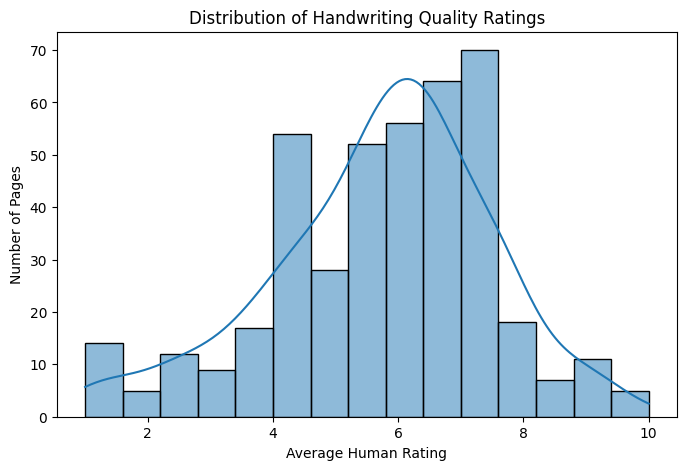

,target
count,422.000000
mean,5.722749
std,1.766380
min,1.000000
25%,4.500000
50%,6.000000
75%,7.000000
max,10.000000


In [28]:
page_ratings = (
    model_df.groupby("source_path", as_index=False)
    .agg(target=("target", "first"), filename=("filename", "first"))
)

plt.figure(figsize=(8, 5))
sns.histplot(page_ratings["target"], bins=15, kde=True)
plt.title("Distribution of Handwriting Quality Ratings")
plt.xlabel("Average Human Rating")
plt.ylabel("Number of Pages")
plt.show()

display(page_ratings.describe())

In [29]:
# First: 15% test set
split1 = GroupShuffleSplit(
    n_splits=1, test_size=0.15, random_state=SEED
)

trainval_idx, test_idx = next(
    split1.split(model_df, groups=model_df["source_path"])
)

trainval_df = model_df.iloc[trainval_idx].copy()
test_df = model_df.iloc[test_idx].copy()

# Then: approximately 15% of the full dataset for validation
val_fraction = 0.15 / 0.85

split2 = GroupShuffleSplit(
    n_splits=1, test_size=val_fraction, random_state=SEED
)

train_idx, val_idx = next(
    split2.split(trainval_df, groups=trainval_df["source_path"])
)

train_df = trainval_df.iloc[train_idx].copy()
val_df = trainval_df.iloc[val_idx].copy()

for name, frame in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(
        f"{name}: {len(frame)} patches | "
        f"{frame['source_path'].nunique()} pages"
    )

train_pages = set(train_df["source_path"])
val_pages = set(val_df["source_path"])
test_pages = set(test_df["source_path"])

assert train_pages.isdisjoint(val_pages)
assert train_pages.isdisjoint(test_pages)
assert val_pages.isdisjoint(test_pages)

print("No page-level leakage detected.")

Train: 8813 patches | 294 pages
Validation: 1853 patches | 64 pages
Test: 1827 patches | 64 pages
No page-level leakage detected.


In [30]:
IMAGE_SIZE = 224
BATCH_SIZE = 32

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomRotation(degrees=3),
    transforms.ColorJitter(brightness=0.08, contrast=0.08),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [31]:
class HandwritingDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]

        image = Image.open(row["patch_path"]).convert("RGB")

        if self.transform:
            image = self.transform(image)

        target = torch.tensor(
            float(row["target"]), dtype=torch.float32
        )

        return image, target, index


train_dataset = HandwritingDataset(train_df, train_transform)
val_dataset = HandwritingDataset(val_df, eval_transform)
test_dataset = HandwritingDataset(test_df, eval_transform)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE,
    shuffle=True, num_workers=2, pin_memory=True
)

val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=2, pin_memory=True
)

test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=2, pin_memory=True
)

print("DataLoaders created.")

DataLoaders created.


In [32]:
try:
    weights = models.EfficientNet_B0_Weights.DEFAULT
    model = models.efficientnet_b0(weights=weights)
    print("Loaded pretrained ImageNet weights.")
except Exception as error:
    print("Could not load pretrained weights:", error)
    print("Using randomly initialized weights.")
    model = models.efficientnet_b0(weights=None)

in_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(in_features, 1)

model = model.to(DEVICE)

print(model.classifier)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 113MB/s] 


Loaded pretrained ImageNet weights.
Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=1, bias=True)
)


In [33]:
criterion = nn.SmoothL1Loss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

EPOCHS = 30
PATIENCE = 6

In [34]:
def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train() if training else model.eval()

    total_loss = 0.0
    total_samples = 0

    all_targets = []
    all_predictions = []

    for images, targets, _ in loader:
        images = images.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            predictions = model(images).squeeze(1)
            loss = criterion(predictions, targets)

            if training:
                loss.backward()
                optimizer.step()

        batch_size = len(targets)
        total_loss += loss.item() * batch_size
        total_samples += batch_size

        all_targets.extend(targets.detach().cpu().numpy())
        all_predictions.extend(predictions.detach().cpu().numpy())

    mean_loss = total_loss / max(total_samples, 1)

    return (
        mean_loss,
        np.asarray(all_targets),
        np.asarray(all_predictions)
    )

In [35]:
history = {
    "train_loss": [],
    "val_loss": []
}

best_val_loss = float("inf")
best_state = None
epochs_without_improvement = 0

for epoch in range(EPOCHS):
    train_loss, _, _ = run_epoch(
        model, train_loader, optimizer
    )

    val_loss, _, _ = run_epoch(model, val_loader)

    scheduler.step(val_loss)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0

        torch.save(
            best_state,
            OUTPUT_DIR / "best_efficientnet_b0.pth"
        )
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping triggered.")
        break

if best_state is None:
    raise RuntimeError("Training did not produce a valid checkpoint.")

model.load_state_dict(best_state)

with open(OUTPUT_DIR / "training_history.json", "w") as file:
    json.dump(history, file, indent=2)

print("Training completed. Best validation loss:", best_val_loss)

Epoch 01/30 | Train Loss: 1.2458 | Val Loss: 0.5831
Epoch 02/30 | Train Loss: 0.4304 | Val Loss: 0.5070
Epoch 03/30 | Train Loss: 0.3450 | Val Loss: 0.4964
Epoch 04/30 | Train Loss: 0.2872 | Val Loss: 0.5473
Epoch 05/30 | Train Loss: 0.2582 | Val Loss: 0.4679
Epoch 06/30 | Train Loss: 0.2193 | Val Loss: 0.4622
Epoch 07/30 | Train Loss: 0.2004 | Val Loss: 0.4196
Epoch 08/30 | Train Loss: 0.1784 | Val Loss: 0.4374
Epoch 09/30 | Train Loss: 0.1638 | Val Loss: 0.4576
Epoch 10/30 | Train Loss: 0.1616 | Val Loss: 0.4089
Epoch 11/30 | Train Loss: 0.1483 | Val Loss: 0.4062
Epoch 12/30 | Train Loss: 0.1372 | Val Loss: 0.3804
Epoch 13/30 | Train Loss: 0.1232 | Val Loss: 0.4147
Epoch 14/30 | Train Loss: 0.1201 | Val Loss: 0.4036
Epoch 15/30 | Train Loss: 0.1104 | Val Loss: 0.4912
Epoch 16/30 | Train Loss: 0.0966 | Val Loss: 0.3857
Epoch 17/30 | Train Loss: 0.0920 | Val Loss: 0.4225
Epoch 18/30 | Train Loss: 0.0889 | Val Loss: 0.4000
Early stopping triggered.
Training completed. Best validation lo

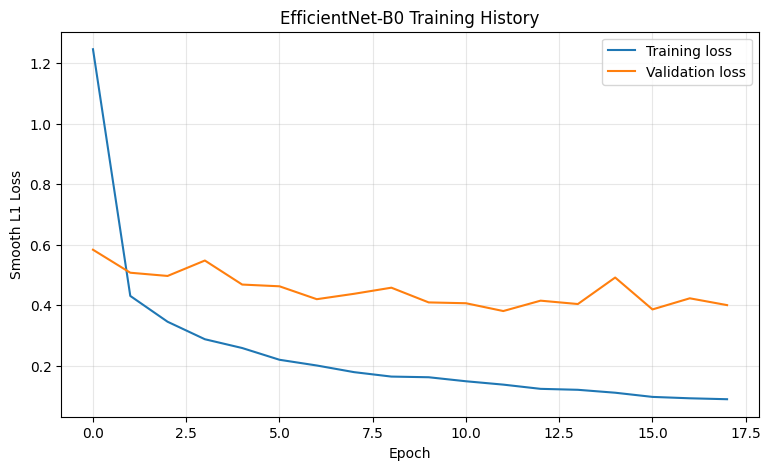

In [36]:
plt.figure(figsize=(9, 5))

plt.plot(history["train_loss"], label="Training loss")
plt.plot(history["val_loss"], label="Validation loss")

plt.xlabel("Epoch")
plt.ylabel("Smooth L1 Loss")
plt.title("EfficientNet-B0 Training History")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [37]:
test_loss, y_true, y_pred = run_epoch(model, test_loader)

mae = mean_absolute_error(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))
r2 = r2_score(y_true, y_pred) if len(y_true) > 1 else float("nan")

print(f"Patch-level MAE:  {mae:.4f}")
print(f"Patch-level RMSE: {rmse:.4f}")
print(f"Patch-level R²:   {r2:.4f}")

Patch-level MAE:  0.7615
Patch-level RMSE: 0.9865
Patch-level R²:   0.4179


In [38]:
test_results = test_df.reset_index(drop=True).copy()
test_results["predicted_rating"] = y_pred

page_results = (
    test_results.groupby("source_path", as_index=False)
    .agg(
        actual_rating=("target", "first"),
        predicted_rating=("predicted_rating", "mean"),
        filename=("filename", "first"),
        patch_count=("predicted_rating", "size")
    )
)

page_mae = mean_absolute_error(
    page_results["actual_rating"],
    page_results["predicted_rating"]
)

page_rmse = np.sqrt(mean_squared_error(
    page_results["actual_rating"],
    page_results["predicted_rating"]
))

page_r2 = (
    r2_score(page_results["actual_rating"], page_results["predicted_rating"])
    if len(page_results) > 1 else float("nan")
)

print(f"Page-level MAE:  {page_mae:.4f}")
print(f"Page-level RMSE: {page_rmse:.4f}")
print(f"Page-level R²:   {page_r2:.4f}")

page_results.to_csv(
    OUTPUT_DIR / "test_page_predictions.csv",
    index=False
)

display(page_results.head(10))

Page-level MAE:  0.7019
Page-level RMSE: 0.8897
Page-level R²:   0.6407


,source_path,actual_rating,predicted_rating,filename,patch_count
0,/content/drive/MyDrive/ML Handwriting Dataset/...,7.0,6.100993,page001.jpg,24
1,/content/drive/MyDrive/ML Handwriting Dataset/...,8.0,7.412128,page010.jpeg,6
2,/content/drive/MyDrive/ML Handwriting Dataset/...,6.5,6.745374,page016.jpg,63
3,/content/drive/MyDrive/ML Handwriting Dataset/...,7.0,5.019987,page020.jpg,28
4,/content/drive/MyDrive/ML Handwriting Dataset/...,6.5,6.196851,page026.jpg,24
5,/content/drive/MyDrive/ML Handwriting Dataset/...,6.5,5.366251,page031.jpeg,4
6,/content/drive/MyDrive/ML Handwriting Dataset/...,6.5,5.407185,page034.jpeg,9
7,/content/drive/MyDrive/ML Handwriting Dataset/...,3.0,4.317297,page040.jpeg,9
8,/content/drive/MyDrive/ML Handwriting Dataset/...,9.0,8.774745,page056.jpg,30
9,/content/drive/MyDrive/ML Handwriting Dataset/...,9.5,9.078583,page057.jpg,30


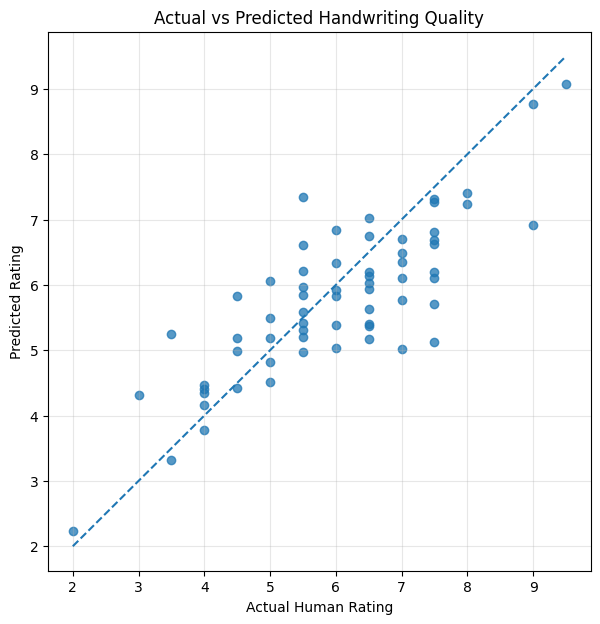

In [39]:
plt.figure(figsize=(7, 7))

plt.scatter(
    page_results["actual_rating"],
    page_results["predicted_rating"],
    alpha=0.75
)

lower = min(
    page_results["actual_rating"].min(),
    page_results["predicted_rating"].min()
)

upper = max(
    page_results["actual_rating"].max(),
    page_results["predicted_rating"].max()
)

plt.plot([lower, upper], [lower, upper], "--")

plt.xlabel("Actual Human Rating")
plt.ylabel("Predicted Rating")
plt.title("Actual vs Predicted Handwriting Quality")
plt.grid(alpha=0.3)
plt.show()

,source_path,actual_rating,predicted_rating,filename,patch_count,absolute_error
30,/content/drive/MyDrive/ML Handwriting Dataset/...,7.5,5.132151,page185.jpg,48,2.367849
58,/content/drive/MyDrive/ML Handwriting Dataset/...,9.0,6.918633,page378.jpeg,12,2.081367
3,/content/drive/MyDrive/ML Handwriting Dataset/...,7.0,5.019987,page020.jpg,28,1.980013
54,/content/drive/MyDrive/ML Handwriting Dataset/...,5.5,7.340269,page367.jpeg,4,1.840269
13,/content/drive/MyDrive/ML Handwriting Dataset/...,7.5,5.714333,page076.jpeg,24,1.785667
50,/content/drive/MyDrive/ML Handwriting Dataset/...,3.5,5.241728,page350.jpg,63,1.741728
38,/content/drive/MyDrive/ML Handwriting Dataset/...,7.5,6.108820,page240.jpg,40,1.391180
48,/content/drive/MyDrive/ML Handwriting Dataset/...,4.5,5.834733,page328.jpg,48,1.334733
47,/content/drive/MyDrive/ML Handwriting Dataset/...,6.5,5.177526,page318.jpg,40,1.322474
7,/content/drive/MyDrive/ML Handwriting Dataset/...,3.0,4.317297,page040.jpeg,9,1.317297


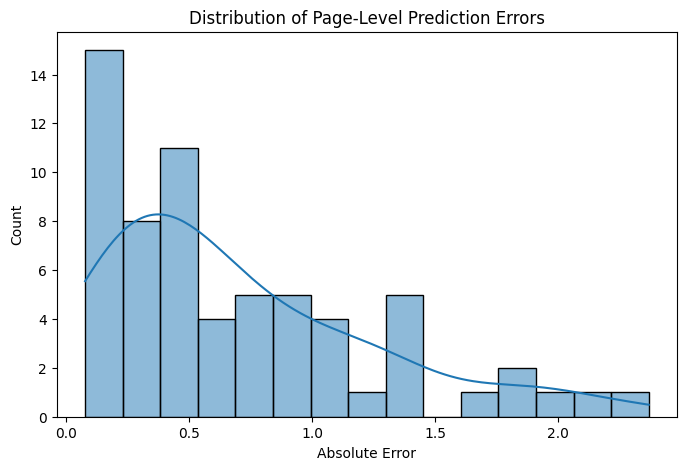

In [40]:
page_results["absolute_error"] = (
    page_results["actual_rating"]
    - page_results["predicted_rating"]
).abs()

display(
    page_results.sort_values(
        "absolute_error", ascending=False
    ).head(15)
)

plt.figure(figsize=(8, 5))
sns.histplot(page_results["absolute_error"], bins=15, kde=True)
plt.title("Distribution of Page-Level Prediction Errors")
plt.xlabel("Absolute Error")
plt.show()

In [41]:
summary = {
    "model": "EfficientNet-B0",
    "task": "Handwriting quality rating regression",
    "patch_size": IMAGE_SIZE,
    "test_pages": int(page_results["source_path"].nunique()),
    "test_patches": int(len(test_df)),
    "page_mae": float(page_mae),
    "page_rmse": float(page_rmse),
    "page_r2": float(page_r2),
    "best_validation_loss": float(best_val_loss)
}

with open(OUTPUT_DIR / "evaluation_summary.json", "w") as file:
    json.dump(summary, file, indent=2)

print(json.dumps(summary, indent=2))
print("\nAll outputs saved to:", OUTPUT_DIR)

{
  "model": "EfficientNet-B0",
  "task": "Handwriting quality rating regression",
  "patch_size": 224,
  "test_pages": 64,
  "test_patches": 1827,
  "page_mae": 0.7019419297575951,
  "page_rmse": 0.889675678845704,
  "page_r2": 0.6407272335752332,
  "best_validation_loss": 0.38039891201856
}

All outputs saved to: /content/drive/MyDrive/ML Handwriting Dataset/dataset/processed/rating_prediction
